## 1. Standardise 2017 and 2026 scene

In [ ]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE" 

import numpy as np
import rasterio                                #read/write rasters (R: terra)
import matplotlib.pyplot as plt                #plots (R: plot)
from pathlib import Path
import geoai

PROJECT = Path("..").resolve()                 
RAW = PROJECT / "data" / "raw" / "raster"
PROC = PROJECT / "data" / "processed"
FIGURES = PROJECT / "results" / "figures"
for p in [PROC, FIGURES]:
    p.mkdir(parents=True, exist_ok=True)      

paths = {
    2017: RAW / "sifnos_2017_psscene_analytic_sr_udm2" / "composite.tif",
    2026: RAW / "sifnos_2026_psscene_analytic_sr_udm2" / "composite.tif",
}

In [ ]:
planet = {}                                    #empty list to fill, one entry per year (R: list())
for year, path in paths.items():              
    with rasterio.open(path) as src:
        planet[year] = src.read()          
        profile = src.profile                
    print(year, planet[year].shape)     

2017 (4, 5582, 3868)
2026 (4, 5582, 3868)


In [8]:
#for each band: 2nd percentile -> 1, 98th percentile -> 255, no data stays 0
#(R: scales::rescale(x, to = c(1, 255), from = quantile(x, c(0.02, 0.98))))
def to_u8(img):
    valid = (img > 0).all(axis=0)              # pixels with data in all 4 bands (R: all bands != 0)
    out = np.zeros(img.shape, dtype="uint8")
    for b in range(img.shape[0]):              # loop over the 4 bands
        low, high = np.percentile(img[b][valid], (2, 99.8)) 
        scaled = (img[b].astype("float32") - low) / (high - low) * 254 + 1
        out[b][valid] = np.clip(scaled[valid], 1, 255).round()
    return out

planet_u8 = {year: to_u8(img) for year, img in planet.items()}

In [9]:
profile.update(dtype="uint8", nodata=0)      
for year, img in planet_u8.items():
    out = PROC / f"planet_{year}_u8.tif"
    with rasterio.open(out, "w", **profile) as dst:
        dst.write(img)
    print("saved", out.name)

saved planet_2017_u8.tif
saved planet_2026_u8.tif


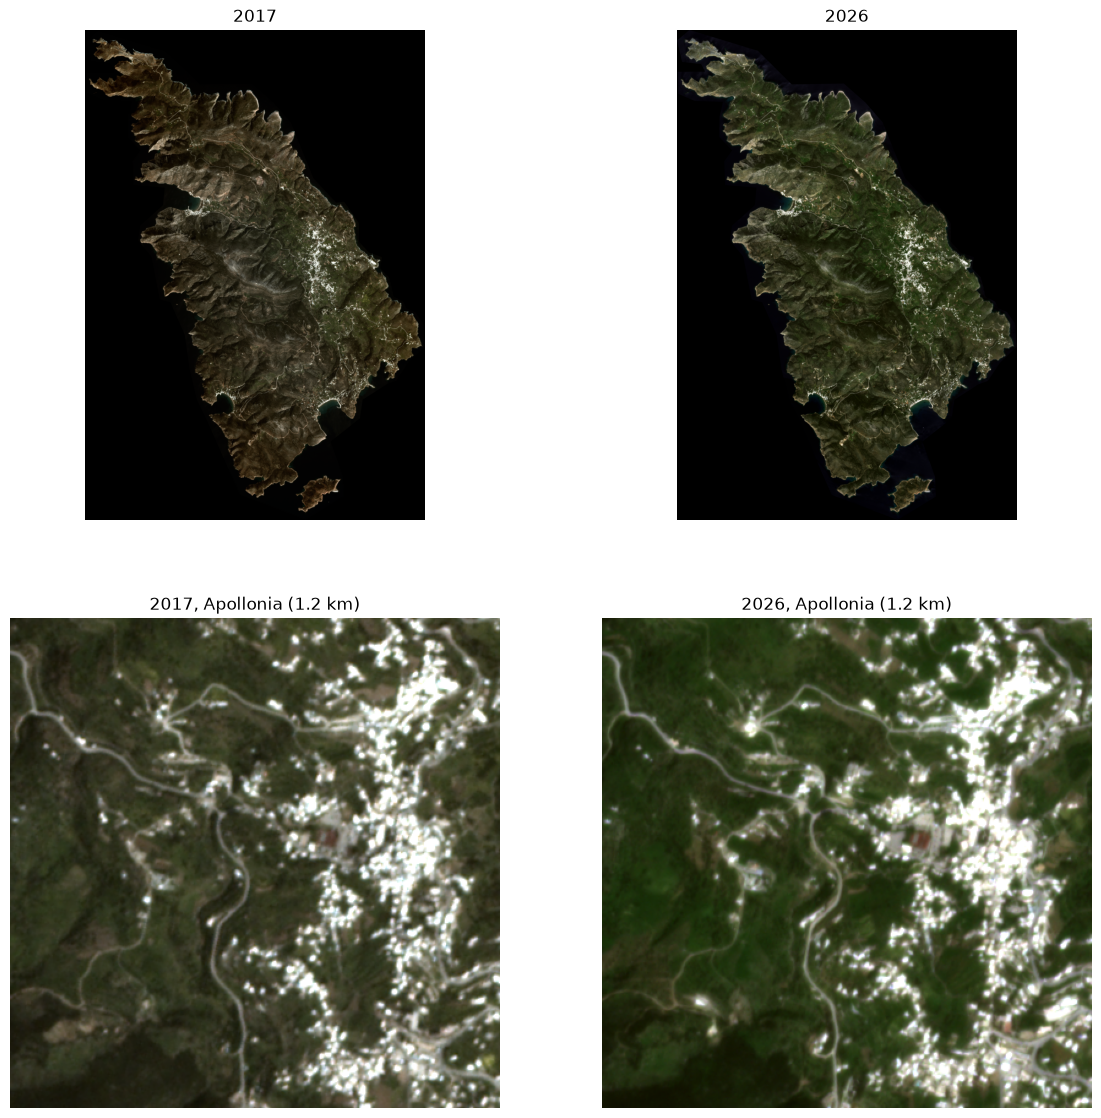

In [10]:
# Apollonia in map coordinates (UTM 35N, metres), turned into a row/column (R: terra::rowColFromCell())
with rasterio.open(PROC / "planet_2026_u8.tif") as src:
    r, c = src.index(297022, 4094341)
z = 200                                        # zoom window: 200 pixels = 600 m on each side

fig, axes = plt.subplots(2, 2, figsize=(14, 14))
for i, year in enumerate([2017, 2026]):
    rgb = planet_u8[year][[2, 1, 0]].transpose(1, 2, 0)   # red, green, blue, as an image (R: plotRGB(r = 3, g = 2, b = 1))
    axes[0, i].imshow(rgb)
    axes[0, i].set_title(f"{year}")
    axes[1, i].imshow(rgb[r - z:r + z, c - z:c + z])
    axes[1, i].set_title(f"{year}, Apollonia (1.2 km)")
for a in axes.flat:
    a.axis("off")
plt.savefig(FIGURES / "planet_2017_2026.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Divide into spatial blocks for training, validating, and testing

In [11]:
import geopandas as gpd                        # vector data (R: library(sf))
from shapely.geometry import box               # make a rectangle (R: st_bbox() %>% st_as_sfc())
from rasterio.windows import from_bounds       # cut a raster by coordinates (R: terra::crop())

VEC = PROJECT / "data" / "raw" / "vectors"
S = 200                                        # square size in Planet pixels (200 x 3 m = 600 m)

with rasterio.open(PROC / "planet_2026_u8.tif") as src:
    T = src.transform                          # links pixels to map coordinates (R: terra::ext() + res())
    CRS = src.crs
    H, W = src.height, src.width
land = planet_u8[2026][0] > 0                  # True where the island is (R: values(r) > 0)
left, top = T.c, T.f                           # top-left corner of the image, in metres

In [12]:
rows = []                                      # one entry per square (R: list(), later bind_rows())
for r in range(0, H - S + 1, S):               # step through the image in 200-pixel jumps
    for c in range(0, W - S + 1, S):
        land_share = land[r:r + S, c:c + S].mean()          # share of the square that is land
        if land_share < 0.3:                   # skip squares that are mostly sea
            continue
        x0, y0 = left + c * 3, top - r * 3     # top-left corner of the square in metres
        rows.append({"row": r, "col": c,
                     "land_share": round(float(land_share), 2),
                     "geometry": box(x0, y0 - S * 3, x0 + S * 3, y0)})

grid = gpd.GeoDataFrame(rows, crs=CRS)         # (R: st_as_sf())
grid["sq_id"] = range(1, len(grid) + 1)        # number the squares 1, 2, 3, ...
print(len(grid), "squares on land")

269 squares on land


In [13]:
# count WorldCover built-up pixels (10 m) in each square, a rough hint where the villages are
with rasterio.open(PROC / "builtup_mask_2021_sifnos.tif") as wc:
    built = []
    for geom in grid.geometry:                 # (R: for (g in st_geometry(grid)))
        win = from_bounds(*geom.bounds, transform=wc.transform)
        built.append(int((wc.read(1, window=win) == 1).sum()))
grid["wc_built_px"] = built                    # 1 pixel = 100 m2

In [14]:
nat_path = sorted(VEC.glob("*.gpkg"))[0]       # the Natura 2000 GeoPackage (R: list.files(pattern = "gpkg"))
print(nat_path.name)
print(gpd.list_layers(nat_path))               # a GeoPackage can hold several tables (R: st_layers())

Natura2000_end2024.gpkg
                  name geometry_type
0   NaturaSite_polygon       Unknown
1            BIOREGION          None
2    DESIGNATIONSTATUS          None
3             HABITATS          None
4         HABITATCLASS          None
5      NATURA2000SITES          None
6         OTHERSPECIES          None
7             METADATA          None
8               IMPACT          None
9           MANAGEMENT          None
10             SPECIES          None


In [15]:
NAT_LAYER = "NaturaSite_polygon"               # <- the layer name printed above

area = gpd.GeoSeries([box(*grid.total_bounds)], crs=CRS)    # only read the part around Sifnos
natura = gpd.read_file(nat_path, layer=NAT_LAYER, bbox=area).to_crs(CRS)
natura = natura.dissolve()                     # merge all sites into one shape (R: st_union())
natura.to_file(PROC / "natura2000_sifnos.gpkg")   # small copy, just Sifnos

inter = grid.geometry.intersection(natura.geometry.iloc[0]).area   # (R: st_intersection(), st_area())
grid["natura_share"] = (inter / grid.geometry.area).round(2)       # 0 = outside, 1 = fully inside
grid["split"] = ""                             # empty column you'll fill in QGIS: train / val / test
grid.to_file(PROC / "squares_600m.gpkg")
print(grid[["sq_id", "land_share", "wc_built_px", "natura_share"]].describe())

            sq_id  land_share  wc_built_px  natura_share
count  269.000000  269.000000   269.000000    269.000000
mean   135.000000    0.950520    79.524164      0.214684
std     77.797815    0.129582   195.554732      0.383784
min      1.000000    0.330000     0.000000      0.000000
25%     68.000000    1.000000     0.000000      0.000000
50%    135.000000    1.000000     3.000000      0.000000
75%    202.000000    1.000000    59.000000      0.250000
max    269.000000    1.000000  1484.000000      1.000000


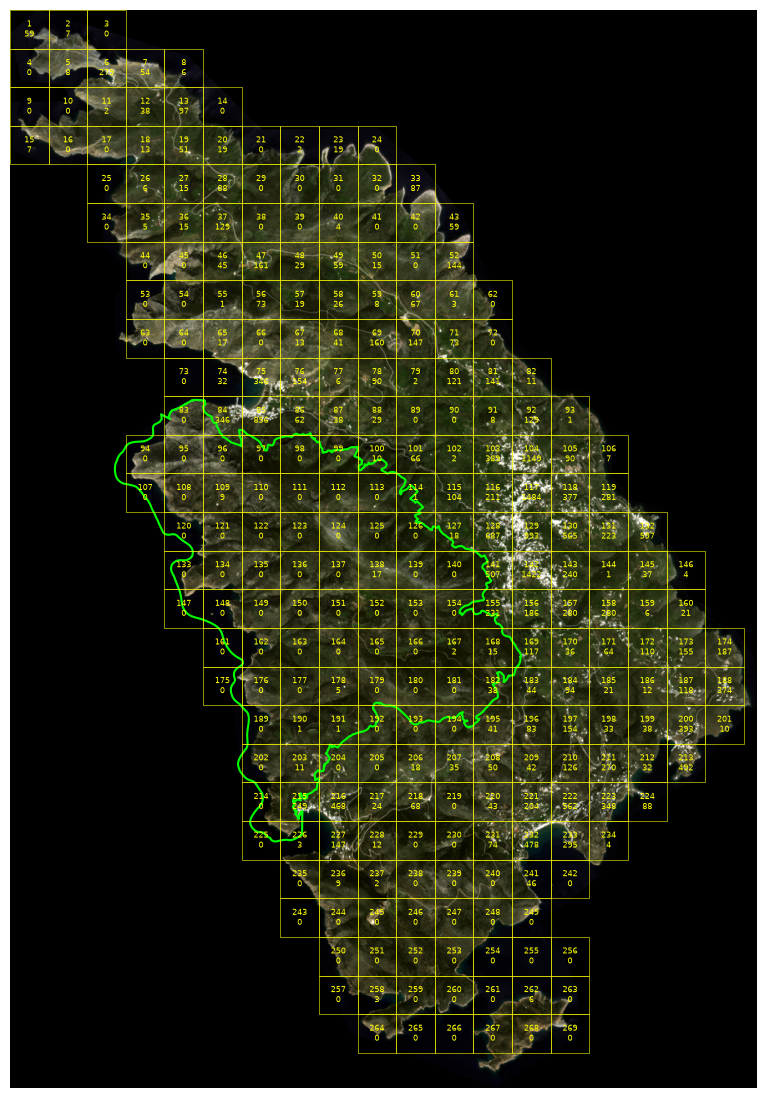

In [16]:
fig, ax = plt.subplots(figsize=(10, 14))
ax.imshow(planet_u8[2026][[2, 1, 0]].transpose(1, 2, 0),
          extent=(left, left + W * 3, top - H * 3, top))           # image in map coordinates
natura.boundary.plot(ax=ax, color="lime", linewidth=1.5)           # Natura 2000 border
grid.boundary.plot(ax=ax, color="yellow", linewidth=0.4)
for _, sq in grid.iterrows():                  # square number + built-up pixels
    x, y = sq.geometry.centroid.coords[0]
    ax.text(x, y, f"{sq.sq_id}\n{sq.wc_built_px}", color="yellow", fontsize=6, ha="center", va="center")
ax.axis("off")
plt.savefig(FIGURES / "squares_600m.png", dpi=200, bbox_inches="tight")
plt.show()

In [21]:
import pandas as pd                            # tables (R: library(dplyr) / tibble)
# 1. describe each square (R: mutate(houses = case_when(...), natura = if_else(...)))
grid["houses"] = pd.cut(grid.wc_built_px, bins=[-1, 0, 99, 1e9], labels=["none", "few", "many"])
grid["natura"] = np.where(grid.natura_share >= 0.5, "inside", "outside")
pool = grid[grid.land_share >= 0.6].copy()                 # only squares with at least 60 % land

# 2. draw squares at random within groups, never the same square twice (R: slice_sample(n = ...))
def draw(candidates, n, seed=42):
    picked = candidates.sample(n=min(n, len(candidates)), random_state=seed)
    pool.drop(picked.index, inplace=True)                  # remove them so they can't be drawn again
    return list(picked.sq_id)

has_houses = pool.wc_built_px >= 50
inside_ok = (pool.natura_share >= 0.25) & (pool.wc_built_px >= 20)       # at least 1/4 Natura, some buildings
outside_ok = (pool.natura_share == 0) & (pool.wc_built_px >= 50)        # fully outside, clear buildings
print("candidates inside:", int(inside_ok.sum()), "| outside:", int(outside_ok.sum()))
test = draw(pool[inside_ok], 2) + draw(pool[outside_ok], 2)
test_area = grid[grid.sq_id.isin(test)].geometry.union_all()     # all test squares as one shape (R: st_union())
pool.drop(pool[pool.intersects(test_area)].index, inplace=True)  # remove squares touching a test square (R: st_intersects())
val = sum([draw(pool[pool.houses == h], 1) for h in ["none", "few", "many"]], [])
train = (draw(pool[pool.houses == "many"], 3) + draw(pool[pool.houses == "few"], 3)
         + draw(pool[pool.houses == "none"], 2))

# 2b. added after the first test (error analysis): the model missed darker, beige roofs on the
#     south coast, so two training squares of that kind were added by hand
extra_train = [232, 233]
touching = grid[grid.sq_id.isin(extra_train)].intersects(test_area)
assert not touching.any(), "an extra square touches a test square"          # (R: stopifnot())
assert not set(extra_train) & set(test + val + train), "an extra square is already used"
train = train + extra_train

# 3. save the choice in the squares file and show it
grid["split"] = ""
grid.loc[grid.sq_id.isin(train), "split"] = "train"
grid.loc[grid.sq_id.isin(val), "split"] = "val"
grid.loc[grid.sq_id.isin(test), "split"] = "test"
grid.drop(columns="houses").to_file(PROC / "squares_600m.gpkg")

chosen = grid[grid.split != ""].sort_values(["split", "sq_id"])
print(chosen[["split", "sq_id", "houses", "natura", "wc_built_px", "natura_share", "land_share"]].to_string(index=False))

candidates inside: 4 | outside: 66
split  sq_id houses  natura  wc_built_px  natura_share  land_share
 test    155   many outside          231          0.31        1.00
 test    211   many outside          270          0.00        1.00
 test    215   many  inside          249          0.59        1.00
 test    227   many outside          147          0.00        1.00
train      1    few outside           59          0.00        0.76
train     46    few outside           45          0.00        1.00
train     59    few outside            8          0.00        1.00
train     69   many outside          160          0.00        1.00
train     97   none  inside            0          0.85        1.00
train    103   many outside          389          0.00        1.00
train    117   many outside         1484          0.00        1.00
train    181   none  inside            0          1.00        1.00
  val     96   none  inside            0          0.91        1.00
  val    200   many outside